In [3]:
whole_smiles = "CC(C)(c1cccc(n1)N2c3c(cnc(n3)Nc4ccc(cc4)N5CCN(CC5)C)C(=O)N2CC=C)O"
scaffold_smiles = None
sim_mode = "desc"
output_dir = f"Ch/{sim_mode}"


In [ ]:
no_rgrp_mols = 10000
top_n = 50


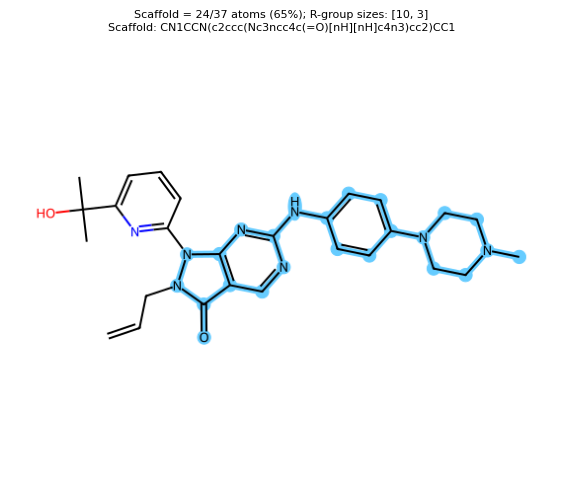

In [4]:
from molshift.tools.rgrp_enum import get_brics_aware_scaffold
if scaffold_smiles is None:
    scaffold_smiles = get_brics_aware_scaffold(whole_smiles, show=True)

In [9]:
from molshift.tools.frag_lib_loader import load_fragment_data

resources = load_fragment_data()
fragment_lib = resources['fragment_desc']

Rgrp Enumeration

In [ ]:
from pathlib import Path
from molshift.tools.rgrp_enum import run_rgrp

rgrp_enum_data = run_rgrp(
    whole_smiles = whole_smiles,
    scaffold_smiles = scaffold_smiles,
    no_rgrp_mols = no_rgrp_mols,
    fragment_desc = fragment_lib,
    sim_mode=sim_mode,
    output_dir = Path(output_dir)/"rgrp_enum")


Total R-groups: 3, Cutoff per site: 22, Total mols: 10648
gate        window                  fail this gate alone   left after (cumulative)
start                                                                      142,993
heavy_atoms [3, 8]                               120,925                    22,068
rings       [0, 0]                               133,582                     6,084
hbd         [0, 0]                                96,702                     2,234
hba         [-1, 1]                              107,509                     1,889
tpsa        [-15, 15]                            124,784                     1,029
fsp3        [0.75, 1.25]                         107,218                       978
n_branch    [1, 4]                                99,129                       961
att=22: ✓ saved 22 fragments → Pirtobrutinib_rgrp_scaff_pipeline\desc\rgrp_enum\Similar_fragments\att_22.csv
gate        window                  fail this gate alone   left after (cumulative)
st

In [11]:
##Outputs of rgrp_enum_data contain the path to the generated molecules as well as the attachment points on the scaffold

rgrp_enum_data

{'output_dir': 'Pirtobrutinib_rgrp_scaff_pipeline\\desc\\rgrp_enum',
 'selected_attachments': [2, 13, 22],
 'Total Generated mols': 8228,
 'Output_path': 'Pirtobrutinib_rgrp_scaff_pipeline\\desc\\rgrp_enum/rgrp_all.csv'}

In [12]:
import pandas as pd

rgrp_enum_df = pd.read_csv(rgrp_enum_data['Output_path'])
selected_atts = rgrp_enum_data['selected_attachments']

### Property-Based Filtering

Only molecules with properties similar to the reference (whole) molecule are retained. Filtering uses a min-max window around each of the reference molecule's property values.

| Property | Mode | Window |
|----------|------|--------|
| MW | relative | ±20 % |
| logP | absolute | ±1.0 |
| HBD | absolute | ±1 |
| HBA | absolute | ±2 |
| TPSA | relative | ±20 % |
| RotB | absolute | ±2 |
| SA | one-sided | ≤ ref_SA + 1.0 (lower = easier to make) |
| QED | one-sided | ≥ ref_QED − 0.10 (higher = more drug-like) |

> **To change these values:** open the `ref_filter` code and edit the `LIPINSKI_BUFFERS` dictionary (`"rel"` = relative fraction, `"abs"` = absolute offset), plus the `SA_BUFFER` and `QED_BUFFER` constants. TPSA and RotB are optional, so comment or uncomment those lines to turn them off or on.

In [13]:
from molshift.tools.ref_filter import filter_by_reference_parallel
import os

filter_1, windows = filter_by_reference_parallel(rgrp_enum_df, "smiles", whole_smiles,n_jobs= os.cpu_count()-4,
                                      sa_buffer=1.0, qed_buffer=0.1)

filter_1.to_csv(Path(output_dir)/"rgrp_enum"/"rgrp_enum_filtered.csv", index=False)



Filtering (12 procs): 100%|██████████| 2/2 [00:16<00:00,  8.10s/it]


Removing Molecules flagged in PAINS or BRENKS alert

In [14]:
from molshift.tools.alerts import filter_alerts

clean, flagged = filter_alerts(filter_1, smiles_col="smiles")
clean.to_csv(Path(output_dir)/"rgrp_enum"/"rgrp_enum_filtered_clean.csv", index=False)

2,087 molecules | invalid SMILES: 0 | removed for alerts: 42 | kept: 2,045
  PAINS  alone flags 0
  BRENK  alone flags 42
  most frequent alerts: {'Aliphatic_long_chain': 42}


Batch Scaff Replacement 

In [ ]:
from molshift.tools.scaff_repl import run_scaff_repl_batch
from pathlib import Path
import os

products = run_scaff_repl_batch(
    molecule_df = clean, 
    smiles_col = "smiles",
    scaffold_smiles = scaffold_smiles,
    selected_atts = selected_atts,
    top_n = top_n,
    resources = resources,
    sim_mode=sim_mode,
    output_dir = Path(output_dir)/"scaff_repl"
)


USRCAT cache loaded: 108,953 vectors
3,376 pass attachment-count + heavy-atom window (18.4-34.5 heavy atoms)
113 pass the bond-distance filter
113 of 113 candidates have a USRCAT vector (reference conformers used: 5)
✓ 113 ranked -> Pirtobrutinib_rgrp_scaff_pipeline\desc\scaff_repl/ranked_scaffolds.csv / .json
50 reactions built from top_n=50 (0 failed to build)
2045 molecules: 2045 processed, 0 without the scaffold pattern, 0 invalid SMILES
✓ 102250 products saved → Pirtobrutinib_rgrp_scaff_pipeline\desc\scaff_repl\scaff_replaced_products_batch.csv


In [16]:
import pandas as pd

scaff_repl_df = pd.read_csv(products['Output_path'])

Ref based Property Filteration

In [17]:
from molshift.tools.ref_filter import filter_by_reference_parallel

filter_2, windows = filter_by_reference_parallel(scaff_repl_df, "product_smiles", whole_smiles,n_jobs = os.cpu_count()-4,
                                      sa_buffer=1.0, qed_buffer=0.1)
filter_2.to_csv(Path(output_dir)/"scaff_repl"/"scaff_repl_filtered.csv", index=False)

Filtering (12 procs): 100%|██████████| 21/21 [01:04<00:00,  3.07s/it]


Removing Molecules with PAINS/BRENK alerts

In [18]:
from molshift.tools.alerts import filter_alerts
from molshift.tools.ref_filter import pick_diverse

clean_2, flagged = filter_alerts(filter_2, smiles_col="product_smiles")
clean_2.to_csv(Path(output_dir)/"scaff_repl"/"scaff_repl_filtered_clean.csv", index=False)

diverse = pick_diverse(clean_2, smiles_col="product_smiles", n=500)

21,451 molecules | invalid SMILES: 0 | removed for alerts: 20 | kept: 21,431
  PAINS  alone flags 20
  BRENK  alone flags 0
  most frequent alerts: {'mannich_A(296)': 20}


In [19]:
clean_2.to_csv(Path(output_dir)/"molshift_generated.csv",index=False)
diverse.to_csv(Path(output_dir)/"molshift_generated_diverse.csv",index=False)

In [20]:
import json, sys, platform, datetime, pathlib

def save_manifest(params: dict, path=f"{output_dir}/manifest.json"):
    manifest = {
        "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "params": params,
    }
    pathlib.Path(path).write_text(json.dumps(manifest, indent=2, default=str))
    return manifest

# Example
params = {
    "Whole smiles": whole_smiles,
    "Scaffold smiles": scaffold_smiles,
    "Similarity screening mode": sim_mode,
    "Number of rgrp replaced": len(selected_atts),
    "Rgrp enumeration mols requested": no_rgrp_mols,
    "Number of rgrp_enum": len(rgrp_enum_df),
    "Rgrp ref based filteration": len(filter_1),
    "Rgrp alerts filteration": len(clean),
    "Scaff repl top_n": top_n,
    "Number of scaff_repl": len(scaff_repl_df),
    "Scaff repl ref based filteration": len(filter_2),
    "Scaff repl alerts filteration": len(clean_2),
}
save_manifest(params)

{'timestamp': '2026-11-14T17:21:26',
 'python': '3.14.2',
 'platform': 'Windows-11-10.0.26200-SP0',
 'params': {'Whole smiles': 'C[C@@H](C(F)(F)F)n1c(c(c(n1)c2ccc(cc2)CNC(=O)c3cc(ccc3OC)F)C(=O)N)N',
  'Scaffold smiles': 'Nc1cc(-c2ccc(CNC(=O)c3cccc(F)c3)cc2)n[nH]1',
  'Similarity screening mode': 'desc',
  'Number of rgrp replaced': 3,
  'Rgrp enumeration mols requested': 10000,
  'Number of rgrp_enum': 8228,
  'Rgrp ref based filteration': 2087,
  'Rgrp alerts filteration': 2045,
  'Scaff repl top_n': 50,
  'Number of scaff_repl': 102250,
  'Scaff repl ref based filteration': 21451,
  'Scaff repl alerts filteration': 21431}}

**Docking**

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import logging
logging.disable(logging.WARNING)
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.warning")
from vina_docking.tools.ligand_docking import run_ligand_docking


dock_config_path = r"dock_config.json"
PROT_DIR = r"Docking_Validations\BTK"
BASE_NAME = "8FLL"
OUT_DIR = Path(output_dir)/"Docking"
LIGAND_FILE = Path(output_dir)/"molshift_generated_diverse.csv"
SMILES_COL = "product_smiles"
K = 30
HAS_REFERENCE = True
SCORE_THRESHOLD = 0.5
REF_PATH = r"Docking_Validations\BTK\REFERENCE"
run_ligand_docking(
        PROT_DIR,
        BASE_NAME,
        OUT_DIR,
        LIGAND_FILE,
        SMILES_COL,
        K,
        HAS_REFERENCE,
        SCORE_THRESHOLD,
        REF_PATH,
        dock_config_path,
    )